# Phase 3: Building and Training the VAE
In this notebook, we define the deep learning architecture for the Variational Autoencoder (VAE) using PyTorch. We will load our preprocessed data and train the model to reconstruct SMILES strings.

In [18]:
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import json
import os
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# Check if GPU is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


## 1. Load Preprocessed Data
We load the `.npy` files and the vocabulary to create PyTorch DataLoaders.

In [19]:
# Load Vocabulary
with open('../data/processed/vocab.json', 'r') as f:
    vocab_data = json.load(f)

char_to_int = vocab_data['char_to_int']
vocab_size = len(char_to_int)

print(f"Vocabulary Size: {vocab_size}")

# Load Training Data
X_train = np.load('../data/processed/X_train.npy')
X_test = np.load('../data/processed/X_test.npy')

# Convert to PyTorch tensors
train_tensor = torch.tensor(X_train, dtype=torch.long)
test_tensor = torch.tensor(X_test, dtype=torch.long)

# Create DataLoaders
BATCH_SIZE = 128
train_dataset = TensorDataset(train_tensor)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

print(f"Batches per epoch: {len(train_loader)}")

Vocabulary Size: 38
Batches per epoch: 1754


## 2. Define the VAE Architecture
The model consists of an **Encoder** (which compresses the SMILES sequence into a small 'latent' vector) and a **Decoder** (which tries to rebuild the SMILES sequence from that vector).

In [20]:
class MolecularVAE(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=256, latent_dim=64):
        super(MolecularVAE, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        
        # ENCODER: reads the sequence
        self.encoder_rnn = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)     # Mean of latent space
        self.fc_var = nn.Linear(hidden_dim, latent_dim)    # Variance of latent space
        
        # DECODER: generates the sequence
        self.decoder_rnn = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.fc_z_to_hidden = nn.Linear(latent_dim, hidden_dim)
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
        
    def encode(self, x):
        embedded = self.embedding(x)
        _, hidden = self.encoder_rnn(embedded) 
        hidden = hidden.squeeze(0) # Get final hidden state
        
        mu = self.fc_mu(hidden)
        logvar = self.fc_var(hidden)
        return mu, logvar
        
    def reparameterize(self, mu, logvar):
        # The Reparameterization Trick: allows backpropagation through random sampling
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
        
    def decode(self, z, dec_input):
        embedded = self.embedding(dec_input)
        
        # The latent vector 'z' sets the initial hidden state for the decoder
        hidden = self.fc_z_to_hidden(z).unsqueeze(0) 
        
        out, _ = self.decoder_rnn(embedded, hidden)
        logits = self.fc_out(out)
        return logits
        
    def forward(self, x):
        # 1. Encode
        mu, logvar = self.encode(x)
        # 2. Sample from latent space
        z = self.reparameterize(mu, logvar)
        # 3. Decode (Teacher Forcing: we feed input x shifted by 1 to predict the next chars)
        dec_input = x[:, :-1]
        logits = self.decode(z, dec_input)
        
        return logits, mu, logvar

model = MolecularVAE(vocab_size=vocab_size).to(device)
print(model)

MolecularVAE(
  (embedding): Embedding(38, 128)
  (encoder_rnn): GRU(128, 256, batch_first=True)
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_var): Linear(in_features=256, out_features=64, bias=True)
  (decoder_rnn): GRU(128, 256, batch_first=True)
  (fc_z_to_hidden): Linear(in_features=64, out_features=256, bias=True)
  (fc_out): Linear(in_features=256, out_features=38, bias=True)
)


## 3. Loss Function
The loss has two parts:
1. **Reconstruction Loss:** How well did it recreate the molecule?
2. **KL Divergence:** How organized is the latent space map?

In [21]:
def vae_loss(logits, targets, mu, logvar, kl_weight=0.05):
    # Flatten the outputs for CrossEntropy
    logits_flat = logits.reshape(-1, logits.size(-1))
    targets_flat = targets.reshape(-1)
    
    # 1. Reconstruction Loss
    recon_loss = F.cross_entropy(logits_flat, targets_flat, reduction='mean')
    
    # 2. KL Divergence
    kld_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    
    total_loss = recon_loss + kl_weight * kld_loss
    return total_loss, recon_loss, kld_loss

## 4. Training Loop
Now we train the model! We will run it for just a few epochs (e.g., 5-10) to make sure it works, but a full model might train for longer.

In [22]:
import glob
import os

EPOCHS = 10
LEARNING_RATE = 0.001
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

loss_history = []

# Auto-detect latest checkpoint to resume automatically
checkpoint_files = glob.glob('../models/checkpoints/vae_epoch_*.pt')
start_epoch = 0
if checkpoint_files:
    # Extract the epoch numbers and find the max
    latest_checkpoint = max(checkpoint_files, key=lambda x: int(x.split('_epoch_')[-1].split('.pt')[0]))
    start_epoch = int(latest_checkpoint.split('_epoch_')[-1].split('.pt')[0])
    print(f'Loading saved checkpoint: {latest_checkpoint}...')
    model.load_state_dict(torch.load(latest_checkpoint, weights_only=True))
    print(f'Successfully loaded! Resuming training from Epoch {start_epoch + 1}...')
else:
    print('No checkpoints found. Starting training from scratch...')

for epoch in range(start_epoch, EPOCHS):
    model.train()
    total_loss_epoch = 0
    
    # Use tqdm for a nice progress bar
    progress_bar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS}')
    
    for batch in progress_bar:
        x = batch[0].to(device)
        
        # Targets are shifted by 1 (we predict the next character)
        targets = x[:, 1:]
        
        # Forward pass
        optimizer.zero_grad()
        logits, mu, logvar = model(x)
        
        # Calculate loss
        loss, recon, kld = vae_loss(logits, targets, mu, logvar)
        
        # Backward pass
        loss.backward()
        # Prevent exploding gradients (common in RNNs)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5)
        optimizer.step()
        
        total_loss_epoch += loss.item()
        progress_bar.set_postfix({'Loss': f'{loss.item():.4f}'})
        
    avg_loss = total_loss_epoch / len(train_loader)
    loss_history.append(avg_loss)
    print(f'Epoch {epoch+1} completed. Average Loss: {avg_loss:.4f}')
    
    # Save a checkpoint every epoch
    torch.save(model.state_dict(), f'../models/checkpoints/vae_epoch_{epoch+1}.pt')

# Save the final model
torch.save(model.state_dict(), '../models/vae_final.pt')
print("\nTraining complete! Final model saved to models/vae_final.pt")

Loading saved checkpoint: ../models/checkpoints\vae_epoch_10.pt...
Successfully loaded! Resuming training from Epoch 11...

Training complete! Final model saved to models/vae_final.pt


## 5. Plot Training Loss
Let's see if our model actually learned by checking if the loss went down.

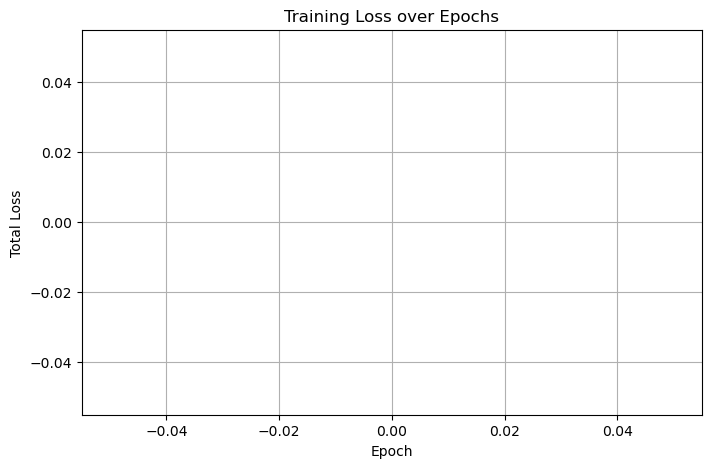

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(loss_history) + 1), loss_history, marker='o', linestyle='-', color='b')
plt.title('Training Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Total Loss')
plt.grid(True)
plt.savefig('../results/plots/loss_curve.png')
plt.show()
